# Part 2 – DistilBERT Model Implementation

## Hate Speech and Offensive Language Classification

**Objective:** Fine-tune the pretrained `distilbert-base-uncased` transformer for the same three-class task as the Part 1 LSTM, and produce outputs that can be compared with it directly in Part 3.

**Classification Categories** (same mapping as Part 1):
- 0 – Hate Speech
- 1 – Offensive Language
- 2 – Neither

**Rules kept from Part 1, so the comparison is fair:**
- The **same train/validation/test split files** from Part 1 (`hate_speech_splits.zip`), checked against their saved SHA-256 hashes.
- The **same class-weighted loss** (inverse class frequency on the training split).
- Model selection by **validation macro-F1**, with early stopping.
- The **test set is evaluated once**, at the end, using the best checkpoint.
- Test predictions are saved **in the same row order** as Part 1's `lstm_test_predictions.csv`.

**Project Workflow:**
1. Setup and loading the shared splits
2. Tokenization with the DistilBERT tokenizer
3. Model configuration for three classes
4. Training and validation pipeline
5. Fine-tuning with early stopping and checkpoint selection
6. Final test evaluation and saved artifacts
7. Inference, sanity tests and latency

**How to run:** In Colab choose *Runtime → Change runtime type → T4 GPU*, then *Runtime → Run all*. Upload `hate_speech_splits.zip` (and optionally `lstm_artifacts.zip`) when asked.
Set `SMOKE_TEST = True` in Section 1 first if you want a quick (~few minutes) end-to-end check on a small sample before the full run.

In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.14.1+cu130
GPU available: True
GPU: Tesla T4


In [2]:
# Install required libraries (Colab already has most of these)

!pip install -q transformers pandas numpy scikit-learn matplotlib seaborn tqdm

In [3]:
# Import required libraries

import os
import re
import sys
import html
import copy
import json
import time
import random
import shutil
import hashlib
import zipfile
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import torch
import torch.nn as nn
import transformers

from sklearn.metrics import (classification_report, confusion_matrix, f1_score,
                             precision_recall_fscore_support)
from torch.utils.data import Dataset, DataLoader
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          DataCollatorWithPadding, get_linear_schedule_with_warmup)
from tqdm.auto import tqdm

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

VERSIONS = {
    'python': platform.python_version(),
    'torch': torch.__version__,
    'transformers': transformers.__version__,
    'scikit-learn': sklearn.__version__,
    'pandas': pd.__version__,
    'numpy': np.__version__,
}
print("All libraries imported successfully!")
print("Running in Colab:", IN_COLAB)
print(json.dumps(VERSIONS, indent=2))

All libraries imported successfully!
Running in Colab: True
{
  "python": "3.13.16",
  "torch": "2.14.1+cu130",
  "transformers": "5.22.1",
  "scikit-learn": "1.6.1",
  "pandas": "2.2.3",
  "numpy": "2.4.6"
}


## 1. Configuration

All settings live in this one cell.

- `SMOKE_TEST = True` trains on a small sample for one epoch. Use it only to check that the notebook runs end to end; its numbers mean nothing. Artifacts from a smoke run go to a separate `..._SMOKE` folder so they can't be confused with the real model.
- Hyperparameters follow the standard BERT fine-tuning recipe: learning rate 2e-5, a few epochs, linear decay with warmup.

In [4]:
SMOKE_TEST = False          # True = quick end-to-end check on a small sample

SEED          = 42
MODEL_NAME    = 'distilbert-base-uncased'
BATCH_SIZE    = 32
LEARNING_RATE = 2e-5
WEIGHT_DECAY  = 0.01
WARMUP_RATIO  = 0.1
MAX_EPOCHS    = 1 if SMOKE_TEST else 4
PATIENCE      = 2           # early stopping: epochs without val macro-F1 improvement
MAX_CHARS     = 1000        # input length limit for predict() (from the project spec)

BASE_DIR  = '/content' if IN_COLAB else os.path.abspath('part2_work')
SPLIT_DIR = f'{BASE_DIR}/processed/splits'
ART_DIR   = f'{BASE_DIR}/distilbert_artifacts' + ('_SMOKE' if SMOKE_TEST else '')
BEST_DIR  = f'{ART_DIR}/best_model'
os.makedirs(SPLIT_DIR, exist_ok=True)
os.makedirs(ART_DIR, exist_ok=True)

# Same label mapping as Part 1
label_mapping = {0: "Hate Speech", 1: "Offensive Language", 2: "Neither"}
target_names  = [label_mapping[i] for i in range(3)]


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    transformers.set_seed(seed)


set_seed()
device  = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = device.type == 'cuda'          # mixed precision on GPU only
print("Device:", device, "| mixed precision:", USE_AMP, "| SMOKE_TEST:", SMOKE_TEST)
print("Artifacts will be saved to:", ART_DIR)

Device: cuda | mixed precision: True | SMOKE_TEST: False
Artifacts will be saved to: /content/distilbert_artifacts


## 2. Load the Shared Splits from Part 1

Upload `hate_speech_splits.zip` from the repository. Optionally also upload `lstm_artifacts.zip`; it is only used at the end to confirm that the test rows line up with the LSTM's test predictions.

The split files are checked against the SHA-256 hashes stored in `split_metadata.json`, which proves this notebook uses exactly the same data as Part 1.

In [5]:
SPLITS_ZIP = 'hate_speech_splits.zip'
LSTM_ZIP   = 'lstm_artifacts.zip'

if IN_COLAB and not os.path.exists(SPLITS_ZIP):
    from google.colab import files
    print("Select hate_speech_splits.zip (and optionally lstm_artifacts.zip):")
    uploaded = files.upload()

if not os.path.exists(SPLITS_ZIP):
    raise FileNotFoundError(
        f"{SPLITS_ZIP} not found in {os.getcwd()}. Upload it from the GitHub repo "
        "(it is created by the Part 1 notebook)."
    )

with zipfile.ZipFile(SPLITS_ZIP) as z:
    z.extractall(SPLIT_DIR)
print("Extracted:", sorted(os.listdir(SPLIT_DIR)))

Extracted: ['split_metadata.json', 'test.csv', 'train.csv', 'val.csv']


In [6]:
# Verify the split files are byte-identical to the ones Part 1 produced

def file_hash(path):
    with open(path, 'rb') as f:
        return hashlib.sha256(f.read()).hexdigest()[:16]

with open(f'{SPLIT_DIR}/split_metadata.json') as f:
    split_meta = json.load(f)

for name in ['train', 'val', 'test']:
    h = file_hash(f'{SPLIT_DIR}/{name}.csv')
    expected = split_meta['sha256_prefix'][name]
    print(f"{name:<5} hash {h}  expected {expected}  {'OK' if h == expected else 'MISMATCH'}")
    assert h == expected, f"{name}.csv does not match Part 1's split. Re-download hate_speech_splits.zip."

# keep_default_na=False: a tweet like "null" or "NA" must stay text, not become NaN
train_df = pd.read_csv(f'{SPLIT_DIR}/train.csv', keep_default_na=False)
val_df   = pd.read_csv(f'{SPLIT_DIR}/val.csv',   keep_default_na=False)
test_df  = pd.read_csv(f'{SPLIT_DIR}/test.csv',  keep_default_na=False)

for name, d in [('train', train_df), ('val', val_df), ('test', test_df)]:
    assert list(d.columns) == ['text', 'label'], name
    assert len(d) == split_meta['sizes'][name], name
    counts = {str(k): int(v) for k, v in d['label'].value_counts().sort_index().items()}
    assert counts == split_meta['class_counts'][name], name
    assert d['text'].str.strip().ne('').all(), name

train_set, val_set, test_set = set(train_df['text']), set(val_df['text']), set(test_df['text'])
assert train_set.isdisjoint(val_set) and train_set.isdisjoint(test_set) and val_set.isdisjoint(test_set)

print(f"\nTrain: {len(train_df):,}  Validation: {len(val_df):,}  Test: {len(test_df):,}")
print("All split checks passed: same files as Part 1, sizes and class counts match, no overlap.")

train hash 11517c687a930d6f  expected 11517c687a930d6f  OK
val   hash 64161650f8f9dee9  expected 64161650f8f9dee9  OK
test  hash 4ce4710f74d0627b  expected 4ce4710f74d0627b  OK

Train: 17,180  Validation: 3,682  Test: 3,682
All split checks passed: same files as Part 1, sizes and class counts match, no overlap.


In [7]:
# SMOKE_TEST only: shrink the data so the whole notebook runs in a few minutes

if SMOKE_TEST:
    train_df = train_df.sample(n=600, random_state=SEED).reset_index(drop=True)
    val_df   = val_df.sample(n=300, random_state=SEED).reset_index(drop=True)
    test_df  = test_df.sample(n=300, random_state=SEED).reset_index(drop=True)
    print("SMOKE TEST: using", len(train_df), "/", len(val_df), "/", len(test_df), "rows")
else:
    print("Full run: using all rows")

Full run: using all rows


## 3. Text Preprocessing and Tokenization

The split files already contain **cleaned** text (Part 1's `clean_text`: HTML entities decoded, lowercased, usernames → `<user>`, URLs → `<url>`). DistilBERT is trained on exactly that text, and `predict()` applies the **same** `clean_text` to new input, so training and inference see the same format.

`distilbert-base-uncased` has its own WordPiece tokenizer, so the LSTM vocabulary is not used here. The placeholders `<user>` and `<url>` are split into pieces like `<`, `user`, `>`, which the model handles fine.

In [8]:
# Identical to Part 1's clean_text (do not change one without the other)

def clean_text(text):

    # Convert HTML entities
    text = html.unescape(str(text))

    # Convert text to lowercase
    text = text.lower()

    # Replace URLs
    text = re.sub(
        r'https?://\S+|www\.\S+',
        ' <url> ',
        text
    )

    # Replace usernames
    text = re.sub(
        r'@\w+',
        ' <user> ',
        text
    )

    # Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    return text


# Consistency check: cleaning already-clean split text should change (almost) nothing,
# so running clean_text inside predict() matches what the model was trained on.
changed = sum(clean_text(t) != t for t in test_df['text'])
print(f"Test texts changed by a second clean_text pass: {changed} of {len(test_df)}")
assert changed / len(test_df) < 0.005

Test texts changed by a second clean_text pass: 0 of 3682


In [9]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
print(type(tokenizer).__name__, "| vocab size:", tokenizer.vocab_size)

for t in train_df['text'].head(3):
    print("\n", t)
    print(tokenizer.tokenize(t))

BertTokenizer | vocab size: 30522

 <user> is little bitch an emotion? cuz i'm feeling it..
['<', 'user', '>', 'is', 'little', 'bitch', 'an', 'emotion', '?', 'cu', '##z', 'i', "'", 'm', 'feeling', 'it', '.', '.']

 okay! rt <user> : right— bitch!!! rt <user> : you mad cause you opened your mouth? #greysanatomy
['okay', '!', 'rt', '<', 'user', '>', ':', 'right', '—', 'bitch', '!', '!', '!', 'rt', '<', 'user', '>', ':', 'you', 'mad', 'cause', 'you', 'opened', 'your', 'mouth', '?', '#', 'grey', '##san', '##ato', '##my']

 rt <user> : when all yo hoes hit you up at da same time.. <url>
['rt', '<', 'user', '>', ':', 'when', 'all', 'yo', 'ho', '##es', 'hit', 'you', 'up', 'at', 'da', 'same', 'time', '.', '.', '<', 'ur', '##l', '>']


count    17180.0
mean        23.6
std         10.1
min          4.0
25%         15.0
50%         23.0
75%         31.0
max         80.0
dtype: float64
90th percentile length: 38
95th percentile length: 40
99th percentile length: 46

MAX_LEN: 48
Tweets truncated in train: 0.42%


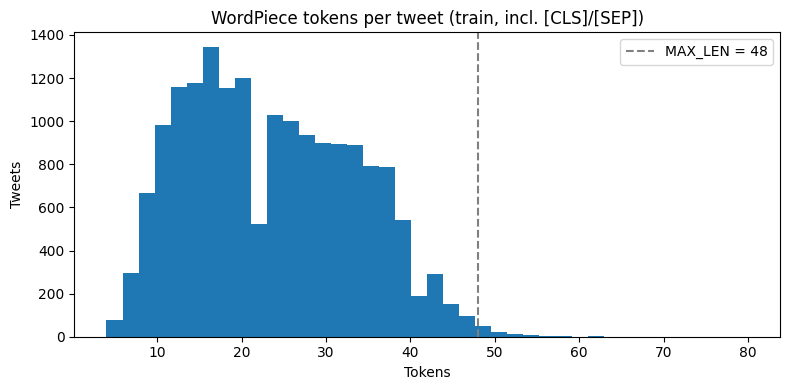

In [10]:
# Choose MAX_LEN from WordPiece lengths on the TRAINING split only

train_lengths = pd.Series([len(ids) for ids in tokenizer(train_df['text'].tolist())['input_ids']])
print(train_lengths.describe().round(1))
for q in [90, 95, 99]:
    print(f"{q}th percentile length: {int(np.percentile(train_lengths, q))}")

p99 = int(np.percentile(train_lengths, 99))
MAX_LEN = min(128, int(np.ceil(p99 / 16) * 16))     # round up to a multiple of 16
print("\nMAX_LEN:", MAX_LEN)
print(f"Tweets truncated in train: {(train_lengths > MAX_LEN).mean() * 100:.2f}%")

plt.figure(figsize=(8, 4))
plt.hist(train_lengths, bins=40)
plt.axvline(MAX_LEN, color='gray', linestyle='--', label=f'MAX_LEN = {MAX_LEN}')
plt.title('WordPiece tokens per tweet (train, incl. [CLS]/[SEP])')
plt.xlabel('Tokens'); plt.ylabel('Tweets'); plt.legend()
plt.tight_layout(); plt.show()

In [11]:
# Datasets and DataLoaders (dynamic padding: each batch is padded to its longest tweet)

class TweetDataset(Dataset):
    def __init__(self, df):
        enc = tokenizer(df['text'].tolist(), truncation=True, max_length=MAX_LEN)
        self.input_ids = enc['input_ids']
        self.attention_mask = enc['attention_mask']
        self.labels = df['label'].astype(int).tolist()

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        return {'input_ids': self.input_ids[i],
                'attention_mask': self.attention_mask[i],
                'labels': self.labels[i]}


collator = DataCollatorWithPadding(tokenizer, return_tensors='pt')
g = torch.Generator().manual_seed(SEED)

train_ds, val_ds, test_ds = TweetDataset(train_df), TweetDataset(val_df), TweetDataset(test_df)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collator, generator=g)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE * 2, shuffle=False, collate_fn=collator)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE * 2, shuffle=False, collate_fn=collator)

batch = next(iter(train_loader))
print({k: tuple(v.shape) for k, v in batch.items()})
assert batch['input_ids'].shape[1] <= MAX_LEN
assert set(batch['labels'].tolist()) <= {0, 1, 2}
print("DataLoader checks passed!")

{'input_ids': (32, 40), 'attention_mask': (32, 40), 'labels': (32,)}
DataLoader checks passed!


## 4. DistilBERT Configuration for Three Classes

`AutoModelForSequenceClassification` loads the pretrained DistilBERT encoder and adds a new, randomly initialised classification head with **3 outputs**. Setting `id2label` / `label2id` stores the label names inside the saved model config.

The warning that some weights are "newly initialized" is expected: that is the new classification head.

In [12]:
def build_model():
    return AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=3,
        id2label=label_mapping,
        label2id={v: k for k, v in label_mapping.items()},
    ).to(device)


set_seed()
model = build_model()
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {n_params:,}")
print("Labels:", model.config.id2label)

# Sanity check: one batch through the untrained model
model.eval()
with torch.no_grad():
    logits = model(input_ids=batch['input_ids'].to(device),
                   attention_mask=batch['attention_mask'].to(device)).logits
print("Output shape:", tuple(logits.shape), f"(expected ({batch['input_ids'].shape[0]}, 3))")
assert logits.shape == (batch['input_ids'].shape[0], 3)
assert torch.isfinite(logits).all()
print("Forward pass OK")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Trainable parameters: 66,955,779
Labels: {0: 'Hate Speech', 1: 'Offensive Language', 2: 'Neither'}
Output shape: (32, 3) (expected (32, 3))
Forward pass OK


In [13]:
# Class-weighted loss: same formula as the LSTM in Part 1

class_counts = np.bincount(train_df['label'].values, minlength=3)
class_weights = len(train_df) / (3.0 * class_counts)          # inverse frequency
class_weights_t = torch.tensor(class_weights, dtype=torch.float32).to(device)

print("Training class counts:", class_counts.tolist())
for i, w in enumerate(class_weights):
    print(f"  weight[{i}] {label_mapping[i]:<20} {w:.3f}")

criterion = nn.CrossEntropyLoss(weight=class_weights_t)

with torch.no_grad():
    init_loss = criterion(logits.float(), batch['labels'].to(device)).item()
print(f"\nInitial loss on one batch: {init_loss:.3f}  (should be near ln(3) = 1.099)")

Training class counts: [989, 13313, 2878]
  weight[0] Hate Speech          5.790
  weight[1] Offensive Language   0.430
  weight[2] Neither              1.990

Initial loss on one batch: 1.104  (should be near ln(3) = 1.099)


## 5. Training and Validation Pipeline

- **Optimizer:** AdamW (no weight decay on biases and LayerNorm weights, as is standard for BERT models).
- **Schedule:** linear warmup over the first 10% of steps, then linear decay to 0.
- **Mixed precision (fp16)** on the GPU for speed; the loss is computed in fp32.
- **Gradient clipping** at 1.0.
- Validation runs in full precision, so it matches the inference function exactly.

In [14]:
def to_device(batch):
    return {k: v.to(device) for k, v in batch.items()}


def evaluate(model, loader):
    # Returns loss, macro-F1, accuracy, predictions, labels and softmax probabilities.
    model.eval()
    total_loss, all_preds, all_labels, all_probs = 0.0, [], [], []
    with torch.no_grad():
        for batch in loader:
            batch = to_device(batch)
            logits = model(input_ids=batch['input_ids'],
                           attention_mask=batch['attention_mask']).logits.float()
            total_loss += criterion(logits, batch['labels']).item() * batch['labels'].size(0)
            all_probs.append(torch.softmax(logits, dim=1).cpu().numpy())
            all_preds.extend(logits.argmax(dim=1).cpu().tolist())
            all_labels.extend(batch['labels'].cpu().tolist())
    avg_loss = total_loss / len(all_labels)
    macro_f1 = f1_score(all_labels, all_preds, average='macro')
    acc = float(np.mean(np.array(all_preds) == np.array(all_labels)))
    return avg_loss, macro_f1, acc, all_preds, all_labels, np.concatenate(all_probs)


def make_scaler():
    # torch.amp.GradScaler is the current API; older PyTorch only has torch.cuda.amp
    if hasattr(torch, 'amp') and hasattr(torch.amp, 'GradScaler'):
        return torch.amp.GradScaler(device.type, enabled=USE_AMP)
    return torch.cuda.amp.GradScaler(enabled=USE_AMP)


def train_one_epoch(model, loader, optimizer, scheduler, scaler, clip=1.0):
    model.train()
    total_loss, n = 0.0, 0
    for batch in tqdm(loader, desc='train', leave=False):
        batch = to_device(batch)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(input_ids=batch['input_ids'],
                           attention_mask=batch['attention_mask']).logits
        loss = criterion(logits.float(), batch['labels'])
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), clip)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        total_loss += loss.item() * batch['labels'].size(0)
        n += batch['labels'].size(0)
    return total_loss / n


def make_optimizer(model):
    no_decay = ['bias', 'LayerNorm.weight']
    groups = [
        {'params': [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)],
         'weight_decay': WEIGHT_DECAY},
        {'params': [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)],
         'weight_decay': 0.0},
    ]
    return torch.optim.AdamW(groups, lr=LEARNING_RATE)


print("Training helpers defined.")

Training helpers defined.


## 6. Fine-Tuning with Early Stopping and Checkpoint Selection

- **Selection metric:** validation **macro-F1**, the same as the LSTM.
- After each epoch, if validation macro-F1 improved, the model and tokenizer are saved with `save_pretrained()` to `best_model/`.
- Training stops early if macro-F1 hasn't improved for `PATIENCE` epochs.
- The **test set is not touched here.**

In [15]:
# Training loop (fresh model + optimizer so this cell is safe to re-run)

set_seed()
model = build_model()
optimizer = make_optimizer(model)
total_steps = len(train_loader) * MAX_EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_RATIO * total_steps), total_steps)
scaler = make_scaler()

hyperparameters = {
    'model_name': MODEL_NAME, 'max_len': MAX_LEN, 'batch_size': BATCH_SIZE,
    'learning_rate': LEARNING_RATE, 'weight_decay': WEIGHT_DECAY, 'warmup_ratio': WARMUP_RATIO,
    'max_epochs': MAX_EPOCHS, 'patience': PATIENCE, 'fp16': USE_AMP,
    'class_weights': [round(float(w), 4) for w in class_weights], 'seed': SEED,
    'smoke_test': SMOKE_TEST,
}

history = []
best_f1, best_epoch, epochs_without_improvement = -1.0, 0, 0
train_start = time.time()

print(f"{'Epoch':>5} | {'Train loss':>10} | {'Val loss':>8} | {'Val acc':>7} | {'Val macro-F1':>12} | {'LR':>9} | {'Time':>6}")
print("-" * 78)

for epoch in range(1, MAX_EPOCHS + 1):
    t0 = time.time()
    train_loss = train_one_epoch(model, train_loader, optimizer, scheduler, scaler)
    val_loss, val_f1, val_acc, _, _, _ = evaluate(model, val_loader)
    lr = optimizer.param_groups[0]['lr']
    secs = time.time() - t0

    history.append({'epoch': epoch, 'train_loss': train_loss, 'val_loss': val_loss,
                    'val_acc': val_acc, 'val_macro_f1': val_f1, 'lr': lr, 'seconds': secs})

    flag = ""
    if val_f1 > best_f1:
        best_f1, best_epoch, epochs_without_improvement = val_f1, epoch, 0
        model.save_pretrained(BEST_DIR)
        tokenizer.save_pretrained(BEST_DIR)
        with open(f'{BEST_DIR}/train_info.json', 'w') as f:
            json.dump({'epoch': epoch, 'val_macro_f1': val_f1, 'max_len': MAX_LEN,
                       'label_mapping': label_mapping, 'hyperparameters': hyperparameters,
                       'versions': VERSIONS}, f, indent=2)
        flag = "  <- best, saved"
    else:
        epochs_without_improvement += 1

    print(f"{epoch:>5} | {train_loss:>10.4f} | {val_loss:>8.4f} | {val_acc:>7.4f} | {val_f1:>12.4f} | {lr:>9.2e} | {secs:>5.0f}s{flag}")

    if epochs_without_improvement >= PATIENCE:
        print(f"\nEarly stopping: no improvement for {PATIENCE} epochs.")
        break

TRAIN_MINUTES = (time.time() - train_start) / 60
print(f"\nBest validation macro-F1: {best_f1:.4f} at epoch {best_epoch}")
print(f"Total training time: {TRAIN_MINUTES:.1f} min")
print("Checkpoint:", BEST_DIR)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch | Train loss | Val loss | Val acc | Val macro-F1 |        LR |   Time
------------------------------------------------------------------------------


train:   0%|          | 0/537 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

    1 |     0.6685 |   0.5170 |  0.8620 |       0.7305 |  1.67e-05 |    49s  <- best, saved


... (4 outputs left out)

    3 |     0.3332 |   0.5505 |  0.8791 |       0.7480 |  5.55e-06 |    40s  <- best, saved


train:   0%|          | 0/537 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

    4 |     0.2599 |   0.6498 |  0.8933 |       0.7579 |  0.00e+00 |    37s  <- best, saved

Best validation macro-F1: 0.7579 at epoch 4
Total training time: 2.9 min
Checkpoint: /content/distilbert_artifacts/best_model


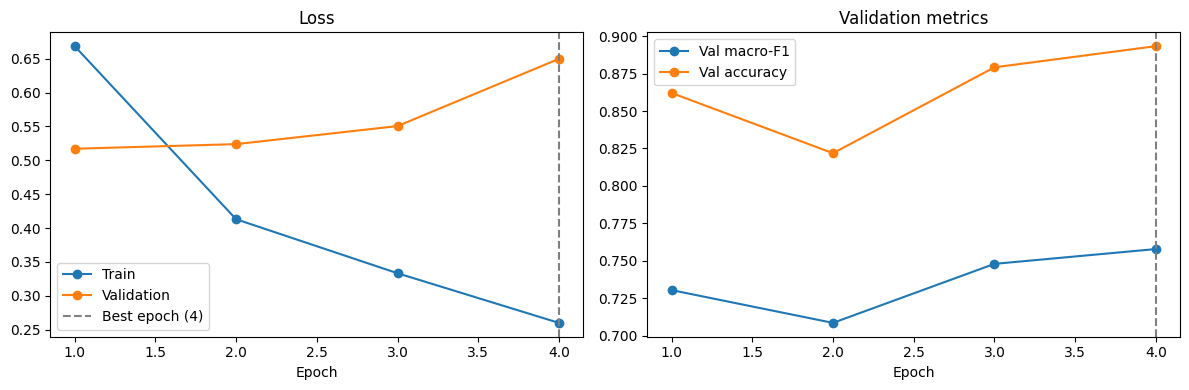

In [16]:
# Training curves

hist = pd.DataFrame(history)
hist.to_csv(f'{ART_DIR}/training_history.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(hist['epoch'], hist['train_loss'], marker='o', label='Train')
axes[0].plot(hist['epoch'], hist['val_loss'], marker='o', label='Validation')
axes[0].axvline(best_epoch, color='gray', linestyle='--', label=f'Best epoch ({best_epoch})')
axes[0].set_title('Loss'); axes[0].set_xlabel('Epoch'); axes[0].legend()

axes[1].plot(hist['epoch'], hist['val_macro_f1'], marker='o', label='Val macro-F1')
axes[1].plot(hist['epoch'], hist['val_acc'], marker='o', label='Val accuracy')
axes[1].axvline(best_epoch, color='gray', linestyle='--')
axes[1].set_title('Validation metrics'); axes[1].set_xlabel('Epoch'); axes[1].legend()

plt.tight_layout()
plt.savefig(f'{ART_DIR}/training_curves.png', dpi=150)
plt.show()

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Best checkpoint (epoch 4) -> val loss 0.6498 | val acc 0.8933 | val macro-F1 0.7579

                    precision    recall  f1-score   support

       Hate Speech      0.366     0.557     0.442       212
Offensive Language      0.965     0.909     0.936      2853
           Neither      0.858     0.937     0.895       617

          accuracy                          0.893      3682
         macro avg      0.730     0.801     0.758      3682
      weighted avg      0.913     0.893     0.901      3682



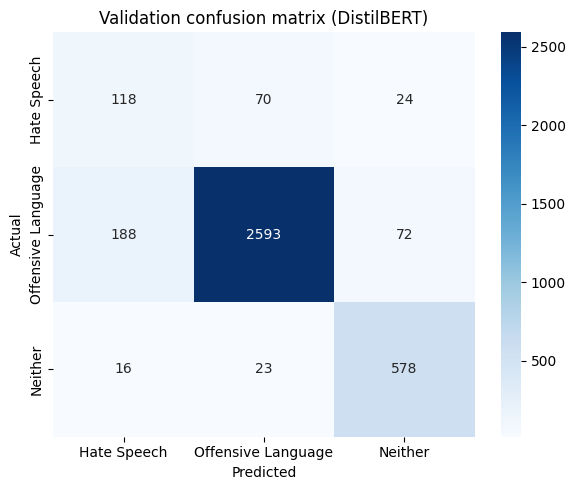

In [17]:
# Reload the best checkpoint FROM DISK and report on the VALIDATION set (test set stays untouched)

best_model = AutoModelForSequenceClassification.from_pretrained(BEST_DIR).to(device)
with open(f'{BEST_DIR}/train_info.json') as f:
    best_info = json.load(f)

val_loss, val_f1, val_acc, val_preds, val_labels, _ = evaluate(best_model, val_loader)
print(f"Best checkpoint (epoch {best_info['epoch']}) -> val loss {val_loss:.4f} | val acc {val_acc:.4f} | val macro-F1 {val_f1:.4f}\n")
assert abs(val_f1 - best_info['val_macro_f1']) < 1e-3, "Reloaded checkpoint does not reproduce the saved val score"

print(classification_report(val_labels, val_preds, labels=[0, 1, 2], target_names=target_names, digits=3, zero_division=0))

cm = confusion_matrix(val_labels, val_preds, labels=[0, 1, 2])
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names)
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Validation confusion matrix (DistilBERT)')
plt.tight_layout()
plt.show()

## 7. Final Test Evaluation and Saved Artifacts

- The **test set is evaluated once**, using the best checkpoint chosen on validation. Do not change the model or hyperparameters after looking at these numbers.
- Outputs use the same file layout and JSON keys as the LSTM's, so Part 3 can compare them directly:
  - `distilbert_test_predictions.csv`: `text`, `label`, `distilbert_pred`, `correct` plus one probability column per class, in the same row order as `test.csv`.
  - `distilbert_test_results.json`: same keys as `lstm_test_results.json`, plus per-class precision/recall and the confusion matrix.

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Checkpoint from epoch 4 (val macro-F1 0.7579)

TEST  loss 0.6150 | accuracy 0.8903 | macro-F1 0.7558 | weighted-F1 0.8980

                    precision    recall  f1-score   support

       Hate Speech      0.370     0.561     0.446       212
Offensive Language      0.965     0.904     0.934      2854
           Neither      0.843     0.938     0.888       616

          accuracy                          0.890      3682
         macro avg      0.726     0.801     0.756      3682
      weighted avg      0.910     0.890     0.898      3682



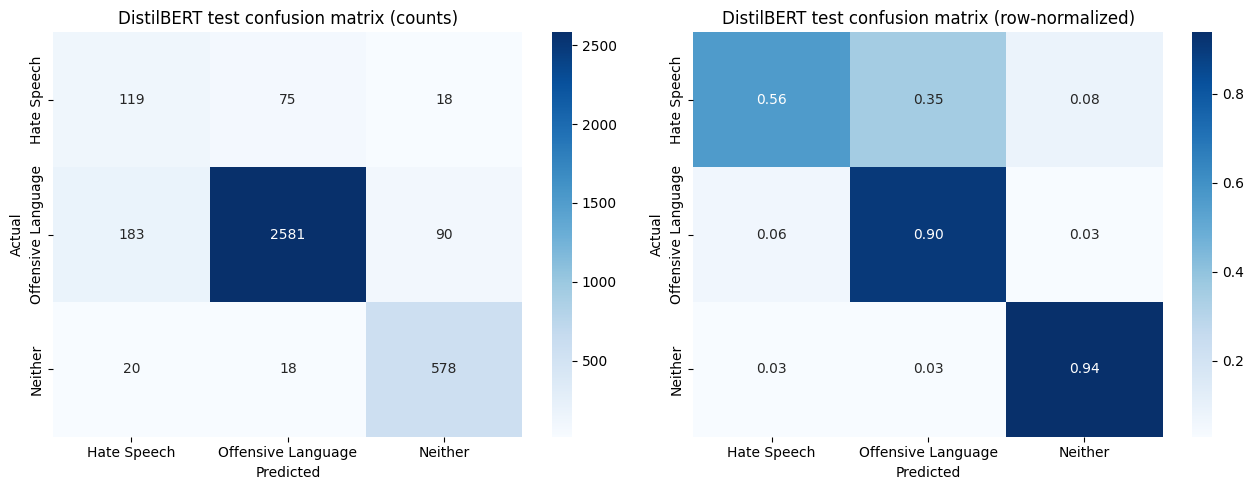

In [18]:
# One-time evaluation on the held-out TEST set

final_model = AutoModelForSequenceClassification.from_pretrained(BEST_DIR).to(device)

test_loss, test_f1, test_acc, test_preds, test_labels, test_probs = evaluate(final_model, test_loader)
weighted_f1 = f1_score(test_labels, test_preds, average='weighted')

print(f"Checkpoint from epoch {best_info['epoch']} (val macro-F1 {best_info['val_macro_f1']:.4f})\n")
print(f"TEST  loss {test_loss:.4f} | accuracy {test_acc:.4f} | macro-F1 {test_f1:.4f} | weighted-F1 {weighted_f1:.4f}\n")

report_text = classification_report(test_labels, test_preds, labels=[0, 1, 2],
                                    target_names=target_names, digits=3, zero_division=0)
print(report_text)
with open(f'{ART_DIR}/distilbert_classification_report.txt', 'w') as f:
    f.write(report_text)

cm = confusion_matrix(test_labels, test_preds, labels=[0, 1, 2])
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=target_names, yticklabels=target_names)
axes[0].set_title('DistilBERT test confusion matrix (counts)')
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', ax=axes[1],
            xticklabels=target_names, yticklabels=target_names)
axes[1].set_title('DistilBERT test confusion matrix (row-normalized)')
for ax in axes:
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout()
plt.savefig(f'{ART_DIR}/distilbert_confusion_matrix_test.png', dpi=150)
plt.show()

In [19]:
# Save test predictions and metrics (for comparison with the LSTM in Part 3)

pred_df = test_df[['text', 'label']].copy()
pred_df['distilbert_pred'] = test_preds
pred_df['correct'] = (pred_df['label'] == pred_df['distilbert_pred'])
pred_df['prob_hate_speech'] = test_probs[:, 0]
pred_df['prob_offensive_language'] = test_probs[:, 1]
pred_df['prob_neither'] = test_probs[:, 2]
pred_df.to_csv(f'{ART_DIR}/distilbert_test_predictions.csv', index=False)

precision, recall, f1s, support = precision_recall_fscore_support(
    test_labels, test_preds, labels=[0, 1, 2], zero_division=0)

results = {
    'model': 'DistilBERT (distilbert-base-uncased, fine-tuned)',
    'checkpoint_epoch': int(best_info['epoch']),
    'val_macro_f1': float(best_info['val_macro_f1']),
    'test': {
        'loss': float(test_loss),
        'accuracy': float(test_acc),
        'macro_f1': float(test_f1),
        'weighted_f1': float(weighted_f1),
        'per_class_f1': {label_mapping[i]: float(f1s[i]) for i in range(3)},
        'per_class_precision': {label_mapping[i]: float(precision[i]) for i in range(3)},
        'per_class_recall': {label_mapping[i]: float(recall[i]) for i in range(3)},
        'support': {label_mapping[i]: int(support[i]) for i in range(3)},
        'confusion_matrix': cm.tolist(),
    },
    'split_seed': SEED,
    'hyperparameters': hyperparameters,
    'training_minutes': round(TRAIN_MINUTES, 2),
    'versions': VERSIONS,
}
with open(f'{ART_DIR}/distilbert_test_results.json', 'w') as f:
    json.dump(results, f, indent=2)

print(json.dumps({k: results[k] for k in ['model', 'checkpoint_epoch', 'val_macro_f1']}, indent=2))
print(json.dumps(results['test']['per_class_f1'], indent=2))

# A few misclassified Hate Speech tweets, for error analysis in Part 3
missed = pred_df[(pred_df['label'] == 0) & (pred_df['distilbert_pred'] != 0)]
print(f"\nHate Speech tweets missed: {len(missed)} of {(pred_df['label'] == 0).sum()}")
for _, r in missed.head(5).iterrows():
    print(f"  predicted {label_mapping[r['distilbert_pred']]:<18} | {r['text'][:110]}")

{
  "model": "DistilBERT (distilbert-base-uncased, fine-tuned)",
  "checkpoint_epoch": 4,
  "val_macro_f1": 0.7578825165662663
}
{
  "Hate Speech": 0.44569288389513106,
  "Offensive Language": 0.9337916063675832,
  "Neither": 0.8878648233486943
}

Hate Speech tweets missed: 93 of 212
  predicted Offensive Language | <user> shut your legs hoe
  predicted Offensive Language | rt <user> : smh nigga is mildly retarded rt <user> : lmfao rt <user> : if griff wasn’t injuries we’d legit be 
  predicted Offensive Language | <user> my bitch dont want your ugly ass gtfo ol peyton manning lookin ass
  predicted Offensive Language | what these bitches want from a nigga?, like on some dmx shit
  predicted Offensive Language | <user> lmao why ur dad raised u to be a bitch made nigga


## 8. Inference

`predict()` is rebuilt **only from the saved folder** (`best_model/`), which confirms those files are enough to use the model later (in the Gradio app).

It returns the **same dictionary format as the LSTM's `predict()`** in Part 1 (`text`, `label`, `label_name`, `confidence`, `probabilities`), so the app can switch between models without special cases. It rejects empty or overly long input instead of guessing.

In [20]:
# Inference, rebuilt ONLY from the saved files

inf_tokenizer = AutoTokenizer.from_pretrained(BEST_DIR)
inf_model = AutoModelForSequenceClassification.from_pretrained(BEST_DIR).to(device)
inf_model.eval()
with open(f'{BEST_DIR}/train_info.json') as f:
    inf_info = json.load(f)
INF_MAX_LEN = inf_info['max_len']
INF_LABELS = {int(k): v for k, v in inf_model.config.id2label.items()}


def validate_text(text):
    # Raise a clear error for input the model should not be asked to classify.
    if not isinstance(text, str):
        raise TypeError(f"Expected a string, got {type(text).__name__}")
    if not text.strip():
        raise ValueError("Text is empty. Please enter a post to classify.")
    if len(text) > MAX_CHARS:
        raise ValueError(f"Text is {len(text)} characters; the limit is {MAX_CHARS}.")


def predict(texts, model=None, tokenizer=None, batch_size=64):
    # Classify one string or a list of strings. Returns a list of dicts (same format as the LSTM).
    model = model or inf_model
    tokenizer = tokenizer or inf_tokenizer
    if isinstance(texts, str):
        texts = [texts]
    for t in texts:
        validate_text(t)

    model_device = next(model.parameters()).device
    cleaned = [clean_text(t) for t in texts]
    all_probs = []
    with torch.no_grad():
        for i in range(0, len(cleaned), batch_size):
            enc = tokenizer(cleaned[i:i + batch_size], truncation=True, max_length=INF_MAX_LEN,
                            padding=True, return_tensors='pt').to(model_device)
            logits = model(input_ids=enc['input_ids'], attention_mask=enc['attention_mask']).logits
            all_probs.append(torch.softmax(logits.float(), dim=1).cpu().numpy())
    probs = np.concatenate(all_probs)

    out = []
    for text, p in zip(texts, probs):
        k = int(p.argmax())
        out.append({
            'text': text,
            'label': k,
            'label_name': INF_LABELS[k],
            'confidence': round(float(p[k]), 3),
            'probabilities': {INF_LABELS[i]: round(float(p[i]), 3) for i in range(3)},
        })
    return out


# Same demo sentences as the LSTM notebook
demo = [
    "Have a wonderful day everyone, thanks for all the support!",
    "shut up you stupid idiot, nobody asked you",
    "@someone check out this article http://example.com/news",
    "that movie was absolutely terrible",
]
for r in predict(demo):
    print(f"{r['label_name']:<18} ({r['confidence']:.2f})  <-  {r['text']}")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Neither            (0.99)  <-  Have a wonderful day everyone, thanks for all the support!
Hate Speech        (0.94)  <-  shut up you stupid idiot, nobody asked you
Neither            (0.99)  <-  @someone check out this article http://example.com/news
Neither            (0.98)  <-  that movie was absolutely terrible


In [21]:
# Consistency check: saved-file inference must reproduce the evaluation predictions

check = predict(test_df['text'].tolist())
check_preds = [r['label'] for r in check]
match = np.mean(np.array(check_preds) == np.array(test_preds))
print(f"Agreement between predict() and the evaluated model on the test set: {match * 100:.2f}%")
assert match > 0.995, "Inference pipeline does not reproduce evaluation predictions!"
print("Inference pipeline verified.")

Agreement between predict() and the evaluated model on the test set: 100.00%
Inference pipeline verified.


In [22]:
# Sanity tests for predict() (these mirror what the Gradio app will need)

def expect_error(fn, err):
    try:
        fn()
    except err:
        return True
    raise AssertionError(f"Expected {err.__name__}")

r = predict("you are all wonderful people")[0]

# 1. Output format matches the LSTM's predict()
assert set(r) == {'text', 'label', 'label_name', 'confidence', 'probabilities'}
assert set(r['probabilities']) == set(label_mapping.values())
assert r['label'] in (0, 1, 2) and r['label_name'] == label_mapping[r['label']]

# 2. Probabilities are valid and sum to 1 (up to rounding)
assert all(0.0 <= p <= 1.0 for p in r['probabilities'].values())
assert abs(sum(r['probabilities'].values()) - 1.0) < 0.01
assert r['confidence'] == max(r['probabilities'].values())

# 3. Invalid input is rejected, not silently classified
expect_error(lambda: predict(""), ValueError)
expect_error(lambda: predict("    \n "), ValueError)
expect_error(lambda: predict("a" * (MAX_CHARS + 1)), ValueError)
expect_error(lambda: predict(None), TypeError)
expect_error(lambda: predict(["fine text", ""]), ValueError)

# 4. Edge cases that should work
predict("a" * MAX_CHARS)                        # exactly at the limit (gets truncated to MAX_LEN tokens)
predict("ok 👍🔥 café naïve")                    # emoji and accents
predict("!!!")                                  # punctuation only
predict("@user http://t.co/abc")                # only placeholders

# 5. Deterministic, and batching gives the same answer as one-at-a-time
a = predict("this is a test sentence")[0]
b = predict("this is a test sentence")[0]
assert a == b
batch_out = predict(demo)
single_out = [predict(t)[0] for t in demo]
assert [x['label'] for x in batch_out] == [x['label'] for x in single_out]

print("All predict() sanity tests passed!")

All predict() sanity tests passed!


In [23]:
# Inference latency (single text, the way the Gradio app will call it)

def measure_latency(model, n_runs=50, n_warmup=5):
    sample = "this is a sample tweet to measure how long a single prediction takes"
    model_device = next(model.parameters()).device
    for _ in range(n_warmup):
        predict(sample, model=model)
    times = []
    for _ in range(n_runs):
        if model_device.type == 'cuda':
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        predict(sample, model=model)
        if model_device.type == 'cuda':
            torch.cuda.synchronize()
        times.append((time.perf_counter() - t0) * 1000)
    return {'median_ms': round(float(np.median(times)), 2),
            'p95_ms': round(float(np.percentile(times, 95)), 2), 'runs': n_runs}

latency = {}
latency['cpu'] = measure_latency(copy.deepcopy(inf_model).to('cpu').eval(), n_runs=30)
if device.type == 'cuda':
    latency['cuda'] = measure_latency(inf_model)
    latency['gpu_name'] = torch.cuda.get_device_name(0)
latency['cpu_threads'] = torch.get_num_threads()

# Throughput on the whole test set (batched)
t0 = time.perf_counter()
predict(test_df['text'].tolist())
latency['test_set_batched'] = {'device': device.type, 'n_texts': len(test_df),
                               'total_s': round(time.perf_counter() - t0, 2)}

with open(f'{ART_DIR}/distilbert_latency.json', 'w') as f:
    json.dump(latency, f, indent=2)
print(json.dumps(latency, indent=2))

{
  "cpu": {
    "median_ms": 59.66,
    "p95_ms": 74.86,
    "runs": 30
  },
  "cuda": {
    "median_ms": 6.51,
    "p95_ms": 8.95,
    "runs": 50
  },
  "gpu_name": "Tesla T4",
  "cpu_threads": 1,
  "test_set_batched": {
    "device": "cuda",
    "n_texts": 3682,
    "total_s": 4.84
  }
}


In [24]:
# Optional: confirm the test rows line up with the LSTM's saved test predictions (needs lstm_artifacts.zip)

if os.path.exists(LSTM_ZIP) and not SMOKE_TEST:
    with zipfile.ZipFile(LSTM_ZIP) as z:
        with z.open('lstm_test_predictions.csv') as f:
            lstm_df = pd.read_csv(f, keep_default_na=False)
    assert lstm_df['text'].tolist() == pred_df['text'].tolist(), "Test row order differs from the LSTM's!"
    assert lstm_df['label'].tolist() == pred_df['label'].tolist()
    agree = (lstm_df['lstm_pred'].values == pred_df['distilbert_pred'].values).mean()
    print("Test rows match the LSTM's predictions file row by row.")
    print(f"LSTM macro-F1 {f1_score(lstm_df['label'], lstm_df['lstm_pred'], average='macro'):.4f} "
          f"| DistilBERT macro-F1 {test_f1:.4f} | models agree on {agree * 100:.1f}% of test tweets")
    print("(Full comparison is in Part 3.)")
else:
    print("Skipped (lstm_artifacts.zip not uploaded, or SMOKE_TEST is on).")

Test rows match the LSTM's predictions file row by row.
LSTM macro-F1 0.7194 | DistilBERT macro-F1 0.7558 | models agree on 91.2% of test tweets
(Full comparison is in Part 3.)


## 9. Save and Share the Artifacts

The saved model is about **255 MB**, which is over GitHub's 100 MB per-file limit, so **do not commit `model.safetensors` to the repo**. Share it through Google Drive instead (or a GitHub Release / Git LFS). The small files (`*.json`, `*.csv`, `*.png`, `*.txt`) are fine to commit.

`best_model/` contains everything needed to load the model later:
`config.json`, `model.safetensors`, tokenizer files, and `train_info.json` (MAX_LEN, label mapping, hyperparameters, versions).

In [25]:
print("Saved artifacts:")
for root, _, fnames in os.walk(ART_DIR):
    for name in sorted(fnames):
        path = os.path.join(root, name)
        print(f"  {os.path.relpath(path, ART_DIR):<45} {os.path.getsize(path) / 1024:>10.1f} KB")

zip_path = shutil.make_archive(ART_DIR, 'zip', ART_DIR)
print(f"\nZipped to {zip_path} ({os.path.getsize(zip_path) / 1e6:.0f} MB)")

Saved artifacts:
  distilbert_classification_report.txt                 0.4 KB
  distilbert_confusion_matrix_test.png                74.3 KB
  distilbert_latency.json                              0.3 KB
  distilbert_test_predictions.csv                    439.8 KB
  distilbert_test_results.json                         1.6 KB
  training_curves.png                                 90.1 KB
  training_history.csv                                 0.5 KB
  best_model/config.json                               0.8 KB
  best_model/model.safetensors                    261558.2 KB
  best_model/tokenizer.json                          694.8 KB
  best_model/tokenizer_config.json                     0.3 KB
  best_model/train_info.json                           0.7 KB

Zipped to /content/distilbert_artifacts.zip (248 MB)


In [26]:
# Copy to Google Drive (recommended: Colab storage is deleted when the session ends)

SAVE_TO_DRIVE = IN_COLAB and not SMOKE_TEST

if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    DRIVE_DIR = '/content/drive/MyDrive/hate_speech_project'
    os.makedirs(DRIVE_DIR, exist_ok=True)
    shutil.copy(zip_path, DRIVE_DIR)
    print("Copied to", DRIVE_DIR, "- share this folder with your teammate.")
else:
    print("Skipped Drive copy.")

# Uncomment to also download the zip directly (large, can be slow):
# from google.colab import files; files.download(zip_path)

Mounted at /content/drive
Copied to /content/drive/MyDrive/hate_speech_project - share this folder with your teammate.
